# [5.7] Griffin, xLSTM, Hyena and Hybrid Models (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter5_modern_architectures/exercises/part7_griffin_xlstm_hyena/5.7_Griffin_xLSTM_Hyena_and_Hybrid_Models_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter5_modern_architectures/exercises/part7_griffin_xlstm_hyena/5.7_Griffin_xLSTM_Hyena_and_Hybrid_Models_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-5-7) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

A message writes a value at time zero. Eight tokens later, a query asks for it. A local attention window has already dropped the write; a recurrent state may still contain it; a long filter may contain it with the wrong sign. What does “long memory” actually mean for the value read by the model?

By the end of this notebook, you will have shown on a fixed pulse-and-query task how recurrence gates, scalar normalization, matrix addressing and an implicit long filter produce different inspectable memory traces, with wrong-channel and reset controls. You will implement the core RG-LRU/Griffin recurrent block, stabilized sLSTM updates, mLSTM matrix memory, causal FFT convolution, a Hyena order-two operator and a small attention–recurrence stack.

These are supplied-weight computational organisms. There is no architecture leaderboard and no hidden training loop. The complete Griffin/xLSTM/Hyena stacks contain learned projections, normalization, local convolutions and training choices beyond each exposed core. Their shared trained recall/state-tracking comparison and optional RecurrentGemma checkpoint remain pending; the final ledger keeps that ambition visible.

Prerequisites: [5.3] recurrent states, [5.6] parallel/recurrent key–value memory and [1.1] causal attention. CPU float64 is intentional for hand calculations and independent oracles. Do not use a bigger model to resolve a shape or normalization error you can catch on a two-step sequence.

**Study edition:** the default examples are deterministic CPU teaching fixtures. No pretrained model is loaded, no network is used, and no trained-model benchmark or native qualification is claimed. Save a personal copy. Public expected answers make this guided, exposed practice.

**Configured requirements:** `modern.recurrent_gemma_griffin`, `modern.xlstm`, `modern.hyena`, `modern.hybrid_attention_ssm_rnn`. The final bridge ledger distinguishes the implemented core from pending native evidence.

## Content & Learning Objectives

### 1️⃣ Gates decide how a recurrence remembers

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 2️⃣ Scalar and matrix memories in xLSTM

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 3️⃣ Long filters and the Hyena operator

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 4️⃣ A hybrid stack on one controlled memory task

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### ☆ Bonus

Predict a changed condition, inspect an anomaly, and plan the paper-to-model bridge.

## Setup code

In [ ]:
from pathlib import Path
import sys
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

chapter = "chapter5_modern_architectures"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part7_griffin_xlstm_hyena.tests as tests

MAIN = __name__ == "__main__"
# NumPy arrays stay on CPU; float64 makes small analytic comparisons transparent.

# 1️⃣ Gates decide how a recurrence remembers

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Griffin alternates recurrent computation with local attention. Its recurrent block uses a Real-Gated Linear Recurrent Unit (RG-LRU), rather than assuming every token needs a growing global KV cache. The core update is
$$h_t=a_t\odot h_{t-1}+\sqrt{1-a_t^2}\odot(i_t\odot x_t).$$
Here $a_t\in[0,1)$ is a gated recurrence coefficient, $i_t$ an input gate, and every vector has shape `(channel,)`. The square-root factor controls the input/state variance for a stationary scalar recurrence; it is not an output normalization. A larger a retains past state but also changes the gain on a new write. When comparing memory traces we must distinguish raw state from fraction of the initial response.

The stable coefficient parameterization is $\log a_t=-c\,\operatorname{softplus}(\Lambda)\,\sigma(g_t)$ with c=8 in the paper. Our Lambda is the explicit decay parameter under that sign convention. A reset token zeroes the **incoming carry**; it need not erase the current input. The full model's initialization, first-token convention, learned gates and head/block layout require version-specific parity.

We will first test the step, then sequence resets, then compose the recurrent block. A separate local-attention baseline makes the information cutoff visible. This is a mechanism-level comparison with supplied gates, not evidence that one trained family solves the task better.

### Exercise - implement `rg_coefficients`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Compute sigmoid of the recurrence-gate logits and stable softplus of the decay parameter, then exponentiate their negative product. Preserve broadcasting over time and channels. Require positive c. Very positive decay parameters must not overflow inside `log(1+exp(x))`; `np.logaddexp(0,x)` is the stable operation. The output may round to zero or one at extreme logits, which the next step handles explicitly.

In [ ]:
def rg_coefficients(gate_logits, decay_parameter, c=8.0):
    """Stable RG-LRU recurrence coefficients in [0,1]."""
    raise NotImplementedError()


tests.test_rg_coefficients(rg_coefficients)

<details>
<summary>Hint</summary>

At zero logits sigmoid is one half and softplus is log 2, so the coefficient is exp(−4 log 2).

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_rg_coefficients passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def rg_coefficients(gate_logits, decay_parameter, c=8.0):
    """Stable RG-LRU recurrence coefficients in [0,1]."""
    if c<=0:raise ValueError("Positive recurrence scale required")
    gate=np.exp(-np.logaddexp(0.,-np.asarray(gate_logits)))
    return np.exp(-c*np.logaddexp(0.,np.asarray(decay_parameter))*gate)
```
</details>

### Exercise - implement `rg_lru_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Implement the displayed equation. Reject recurrence coefficients outside `[0,1]`; allow the endpoints for analytic controls. The input gate multiplies the current input, not the previous state. With a=0 the state is the gated input; with a=1 it is exactly the old state. Use a nonnegative clipped radicand only to protect endpoint roundoff, not to disguise an invalid coefficient.

In [ ]:
def rg_lru_step(x, previous, a, input_gate):
    """One variance-scaled RG-LRU update with supplied gates."""
    raise NotImplementedError()


tests.test_rg_lru_step(rg_lru_step)

<details>
<summary>Hint</summary>

Check the gain on a fresh scalar write before tracing a long sequence. Dropping the square root changes that gain.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_rg_lru_step passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def rg_lru_step(x, previous, a, input_gate):
    """One variance-scaled RG-LRU update with supplied gates."""
    a=np.asarray(a)
    if np.any((a<0)|(a>1)):raise ValueError("Invalid recurrence coefficient")
    return a*previous+np.sqrt(np.maximum(1-a*a,0))*input_gate*x
```
</details>

### Exercise - implement `rg_lru_scan`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Inputs, coefficients and gates all broadcast to `(time,channel)`. Return every state; initialize with zeros. A true reset at time t clears the carry **before** writing x[t]. Copy reset handling into the scan rather than changing the coefficients, so the current-write gain retains its declared meaning. Tests use a hand-expanded recurrence and a reset carrying a new nonzero write.

In [ ]:
def rg_lru_scan(x, coefficients, input_gates, resets=None):
    """Sequence update with explicit incoming-state resets."""
    raise NotImplementedError()


tests.test_rg_lru_scan(rg_lru_scan)

<details>
<summary>Hint</summary>

A reset at a token with value two should still write 0.6×2. Resetting after the update would wrongly erase that token.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_rg_lru_scan passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def rg_lru_scan(x, coefficients, input_gates, resets=None):
    """Sequence update with explicit incoming-state resets."""
    x=np.asarray(x);a=np.broadcast_to(coefficients,x.shape);g=np.broadcast_to(input_gates,x.shape)
    resets=np.zeros(len(x),bool) if resets is None else np.asarray(resets,bool)
    h=np.zeros(x.shape[1]);out=[]
    for t in range(len(x)):
        if resets[t]:h=np.zeros_like(h)
        h=rg_lru_step(x[t],h,a[t],g[t]);out.append(h.copy())
    return np.asarray(out)
```
</details>

### Exercise - implement `local_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

For each t, include source indices `max(0,t-window+1)` through t. Return `(time,value)` outputs, with dot products scaled by square root of key width. Reject nonpositive windows. The current token counts toward the window size. Use stable softmax within the allowed slice, so future or expired entries never enter the denominator.

In [ ]:
def local_attention(q, k, v, window):
    """Stable causal sliding-window softmax attention."""
    raise NotImplementedError()


tests.test_local_attention(local_attention)

<details>
<summary>Hint</summary>

A window of two means current plus one preceding token, not two preceding tokens plus current.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_local_attention passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def local_attention(q, k, v, window):
    """Stable causal sliding-window softmax attention."""
    if type(window) is not int or window<1:raise ValueError("Positive integer window required")
    out=[]
    for t in range(len(q)):
        start=max(0,t-window+1)
        scores=q[t]@k[start:t+1].T/np.sqrt(q.shape[1])
        weights=np.exp(scores-scores.max());weights/=weights.sum()
        out.append(weights@v[start:t+1])
    return np.asarray(out)
```
</details>

### Exercise - implement `griffin_recurrent_block`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Use `projected=x@W_in`, then a depthwise causal convolution of the projected channels with `conv_kernel` `(kernel_time,expanded_channel)`. Feed the result through the RG-LRU scan. Gate its output by GELU of `x@W_gate`, project with W_out, and add x. Use the tanh GELU approximation explicitly. This isolates the recurrent branch; the full model's RMSNorm, learned grouped gate projections, MLP blocks and stacking schedule are separate native boundaries.

In [ ]:
def griffin_recurrent_block(x, W_in, W_gate, W_out, conv_kernel, coefficients, input_gates):
    """A supplied-weight Griffin recurrent branch with residual addition."""
    raise NotImplementedError()


tests.test_griffin_recurrent_block(griffin_recurrent_block)

<details>
<summary>Hint</summary>

The depthwise convolution does not mix channels. Zero output projection and zero GELU gate should each kill the branch independently.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_griffin_recurrent_block passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def griffin_recurrent_block(x, W_in, W_gate, W_out, conv_kernel, coefficients, input_gates):
    """A supplied-weight Griffin recurrent branch with residual addition."""
    projected=x@W_in
    filtered=np.stack([np.convolve(projected[:,c],conv_kernel[:,c],mode="full")[:len(x)] for c in range(projected.shape[1])],axis=1)
    h=rg_lru_scan(filtered,coefficients,input_gates)
    z=x@W_gate
    gate=.5*z*(1+np.tanh(np.sqrt(2/np.pi)*(z+.044715*z**3)))
    return x+(gate*h)@W_out
```
</details>

## A carry is not the same thing as an attention window


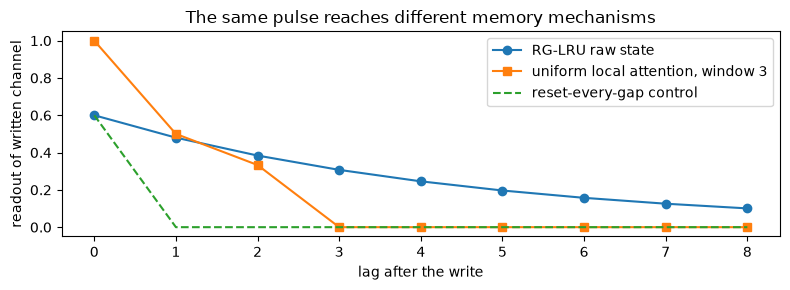

In [ ]:
pulse=np.zeros((9,2));pulse[0,0]=1
rg=rg_lru_scan(pulse,.8,1)
reset=rg_lru_scan(pulse,.8,1,np.arange(9)>0)
att=local_attention(np.zeros_like(pulse),np.zeros_like(pulse),pulse,3)
fig,ax=plt.subplots(figsize=(8,3));ax.plot(rg[:,0],marker="o",label="RG-LRU raw state");ax.plot(att[:,0],marker="s",label="uniform local attention, window 3");ax.plot(reset[:,0],linestyle="--",label="reset-every-gap control");ax.set(xlabel="lag after the write",ylabel="readout of written channel",title="The same pulse reaches different memory mechanisms");ax.legend();fig.tight_layout();plt.show()
print("RG first/final",rg[0,0],rg[-1,0])

<details>
<summary>Help - how should I interpret this?</summary>

The RG write starts at 0.6 because of variance scaling, then decays by 0.8 each token. Local attention averages the pulse while it is in the window and returns zero once it expires. Resetting incoming carry makes the recurrence lose it immediately. The different initial gains matter; these raw curves are not a trained task-accuracy ranking.

</details>

## Summary of 1️⃣

Griffin-style recurrence and local attention have different information paths. Gate coefficients, reset conventions, input scaling and residual composition need separate tests before reasoning about a long memory trace.

# 2️⃣ Scalar and matrix memories in xLSTM

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

xLSTM changes the memory mechanism, not merely the name of an ordinary LSTM. The scalar sLSTM uses exponential input/forget gates and a normalizer:
$$c_t=f_tc_{t-1}+i_tz_t,\quad n_t=f_tn_{t-1}+i_t,\quad h_t=o_t c_t/n_t.$$
The gates are supplied log weights here. Their absolute scale can overflow while their ratio is well behaved, so retain a stabilizer $m_t=\max(\log f_t+m_{t-1},\log i_t)$ and scale both c and n consistently. The full sLSTM also learns recurrent gate dependencies and memory mixing; this exercise exposes the stabilized memory arithmetic with fixed gates.

The mLSTM instead stores a value-by-key matrix $C_t=f_tC_{t-1}+i_tv_tk_t^\top$ and a key normalizer $n_t=f_tn_{t-1}+i_tk_t$. Its readout is $o_t C_tq_t/\max(|n_t^\top q_t|,1)$. We scale keys by square root of their width before writes. The absolute-value/floor normalizer differs from positive-kernel normalization in [5.6]; signed keys can cancel. We will test that case rather than quietly replacing it by a softmax.

Our matrix fixtures use moderate already-activated nonnegative gates; native stabilized exponential mLSTM kernels and checkpoint parity remain pending. Keeping this boundary explicit is more useful than claiming a three-line matrix update is a complete trained xLSTM block.

### Exercise - implement `slstm_step`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

`state` is `(c,n,m)` in scaled units. Return `(hidden,new_state)`. Compute the new maximum log scale, transformed forget/input weights, then update c and n. Divide c by n where positive and multiply by the supplied output gate. Initialize the stabilizer to negative infinity in the scan. A common additive shift of all sequence input log gates should not change the normalized hidden sequence.

In [ ]:
def slstm_step(z, log_i, log_f, output_gate, state):
    """Stabilized scalar/vector sLSTM memory with a shared log scale."""
    raise NotImplementedError()


tests.test_slstm_step(slstm_step)

<details>
<summary>Hint</summary>

Store c and n in the same scaled units. Their ratio cancels the stabilizer; scaling only c corrupts the normalized memory.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_slstm_step passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def slstm_step(z, log_i, log_f, output_gate, state):
    """Stabilized scalar/vector sLSTM memory with a shared log scale."""
    c,n,m=state
    next_m=np.maximum(log_f+m,log_i)
    f=np.exp(log_f+m-next_m);i=np.exp(log_i-next_m)
    next_c=f*c+i*z;next_n=f*n+i
    hidden=output_gate*np.divide(next_c,next_n,out=np.zeros_like(np.asarray(next_c,dtype=float)),where=next_n>0)
    return hidden,(next_c,next_n,next_m)
```
</details>

### Exercise - implement `slstm_scan`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Broadcast log gates and output gates to the `(time,channel)` value array. Initialize c,n to zero and m to negative infinity. Return every hidden value, not the stabilizer. A direct finite-weight oracle enumerates all writes and their intervening forget products. The fixture also shifts every input log gate by 900 to test numerical stability without changing the normalized answer.

In [ ]:
def slstm_scan(values, log_input, log_forget, output_gates=1.0):
    """Return normalized sLSTM memory at every time with supplied log gates."""
    raise NotImplementedError()


tests.test_slstm_scan(slstm_scan)

<details>
<summary>Hint</summary>

Shifting every input weight by one common log constant rescales all writes together. It should cancel in the ratio.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_slstm_scan passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def slstm_scan(values, log_input, log_forget, output_gates=1.0):
    """Return normalized sLSTM memory at every time with supplied log gates."""
    shape=values.shape;li=np.broadcast_to(log_input,shape);lf=np.broadcast_to(log_forget,shape);og=np.broadcast_to(output_gates,shape)
    state=(np.zeros(shape[1]),np.zeros(shape[1]),np.full(shape[1],-np.inf));out=[]
    for t in range(len(values)):
        h,state=slstm_step(values[t],li[t],lf[t],og[t],state);out.append(h.copy())
    return np.asarray(out)
```
</details>

### Exercise - implement `mlstm_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

`q,k` are `(key_dim,)`, `v` `(value_dim,)`; C is `(value_dim,key_dim)` and n `(key_dim,)`. Divide k by `sqrt(key_dim)` before updating both C and n. Use supplied nonnegative activated input/forget gates, then return `(hidden,(C,n))`. Negative gates are invalid. The normalizer is `max(abs(n@q),1)`, not a positive-only sum or Euclidean norm.

In [ ]:
def mlstm_step(q, k, v, input_gate, forget_gate, output_gate, state):
    """mLSTM value-by-key memory with signed denominator floor."""
    raise NotImplementedError()


tests.test_mlstm_step(mlstm_step)

<details>
<summary>Hint</summary>

The key scaling applies to the normalizer as well as the matrix. Use the cancellation fixture to protect the denominator convention.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_mlstm_step passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def mlstm_step(q, k, v, input_gate, forget_gate, output_gate, state):
    """mLSTM value-by-key memory with signed denominator floor."""
    if input_gate<0 or forget_gate<0:raise ValueError("Activated memory gates must be nonnegative")
    C,n=state;scaled_k=k/np.sqrt(len(k))
    C=forget_gate*C+input_gate*np.outer(v,scaled_k)
    n=forget_gate*n+input_gate*scaled_k
    return output_gate*(C@q)/max(abs(float(n@q)),1.),(C,n)
```
</details>

### Exercise - implement `mlstm_scan`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Return `(outputs,C,n)`. Broadcast scalar gates over time. The final state is necessary to continue decoding later. Keep memory shape value-by-key; using key-by-value can pass square one-dimensional tests but fail non-square fixtures. All default gates here are small and finite, so this is the un-stabilized core rather than the paper's complete native kernel.

In [ ]:
def mlstm_scan(q, k, v, input_gates, forget_gates):
    """Sequence mLSTM with supplied activated gates and unit output gate."""
    raise NotImplementedError()


tests.test_mlstm_scan(mlstm_scan)

<details>
<summary>Hint</summary>

The independent oracle sums writes and intervening forget products directly; it never calls a recurrent helper.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_mlstm_scan passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def mlstm_scan(q, k, v, input_gates, forget_gates):
    """Sequence mLSTM with supplied activated gates and unit output gate."""
    T=len(q);ig=np.broadcast_to(input_gates,(T,));fg=np.broadcast_to(forget_gates,(T,))
    state=(np.zeros((v.shape[1],k.shape[1])),np.zeros(k.shape[1]));out=[]
    for t in range(T):
        h,state=mlstm_step(q[t],k[t],v[t],ig[t],fg[t],1.,state);out.append(h)
    return np.asarray(out),state[0],state[1]
```
</details>

### Exercise - implement `mlstm_parallel`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

For every `(t,s)` with s≤t, weight the write by input_gate[s] times all forget gates from s+1 through t. Multiply that by the scaled query/key dot product. Normalize each row by `max(abs(row_sum),1)` and apply to values. Return outputs only. Do not divide by the sum of absolute weights: signed cancellation is part of the declared mechanism.

In [ ]:
def mlstm_parallel(q, k, v, input_gates, forget_gates):
    """Parallel mLSTM core by explicitly enumerating causal gate products."""
    raise NotImplementedError()


tests.test_mlstm_parallel(mlstm_parallel)

<details>
<summary>Hint</summary>

The empty product for a current write is one. The second row of the signed fixture has zero weight sum but nonzero numerator.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_mlstm_parallel passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def mlstm_parallel(q, k, v, input_gates, forget_gates):
    """Parallel mLSTM core by explicitly enumerating causal gate products."""
    T=len(q);ig=np.broadcast_to(input_gates,(T,));fg=np.broadcast_to(forget_gates,(T,));weights=np.zeros((T,T))
    if np.any(ig<0) or np.any(fg<0):raise ValueError("Nonnegative activated gates required")
    for t in range(T):
        for s in range(t+1):weights[t,s]=ig[s]*np.prod(fg[s+1:t+1])
    scores=(q@k.T)/np.sqrt(k.shape[1])*weights
    return (scores@v)/np.maximum(np.abs(scores.sum(1,keepdims=True)),1)
```
</details>

## An exponential gate can revise scalar memory


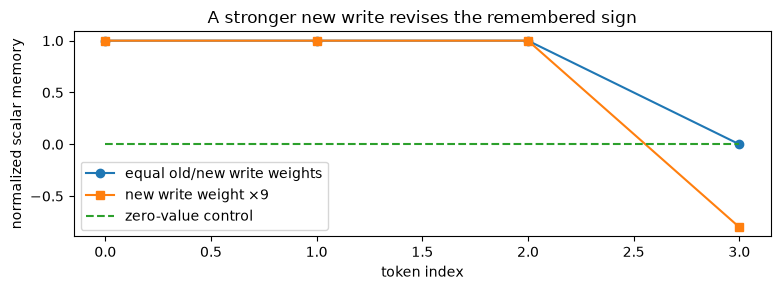

In [ ]:
values=np.array([[1.],[0.],[0.],[-1.]])
base_i=np.array([[0.],[-20.],[-20.],[0.]])
revision_i=base_i.copy();revision_i[-1]=np.log(9.)
base=slstm_scan(values,base_i,0.)[:,0];revised=slstm_scan(values,revision_i,0.)[:,0]
fig,ax=plt.subplots(figsize=(8,3));ax.plot(base,marker="o",label="equal old/new write weights");ax.plot(revised,marker="s",label="new write weight ×9");ax.plot(slstm_scan(np.zeros_like(values),revision_i,0.)[:,0],linestyle="--",label="zero-value control");ax.set(xlabel="token index",ylabel="normalized scalar memory",title="A stronger new write revises the remembered sign");ax.legend();fig.tight_layout();plt.show();print("final equal/reweighted",base[-1],revised[-1])

<details>
<summary>Help - how should I interpret this?</summary>

The equal-weight writes nearly cancel at the final step, while weighting the new −1 write nine times yields about −0.8. Gap input gates are exp(−20), so the exact reference is close to, rather than exactly, that hand limit. The gate is supplied by us, not learned: this demonstrates the memory update capability without attributing a trained policy to xLSTM.

</details>

## Summary of 2️⃣

sLSTM uses an exponentially gated normalized scalar memory; mLSTM stores value–key associations in a matrix. Their normalizers and stabilization requirements differ. Matching parallel/recurrent core equations is a useful semantic gate, not native checkpoint parity.

# 3️⃣ Long filters and the Hyena operator

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

A causal convolution can remember an old write without a recurrent state update: $y_t=\sum_{s\leq t}h_{t-s}x_s$. For long sequences, FFT multiplication computes the same linear convolution efficiently, provided we pad to avoid circular wraparound. The filter h can be generated from positions by a small network instead of storing one parameter per lag. That is an implicit parameterization; the network parameters remain fixed when length changes.

Our filter generator takes normalized time and sine/cosine position coordinates, applies a sine-activated MLP, then an exponential decay window. This exposes the implicit-filter idea used by Hyena without claiming its full positional embeddings, learned modulation or short-convolution stack. A filter can be signed and oscillatory. “Long support” is therefore different from “the old value remains positive and decodable.”

The order-two Hyena operator interleaves two long convolutions with two input-dependent diagonal gates: $y=x_2\odot(h_2*(x_1\odot(h_1*v)))$. If the gates depend on the current input, the complete map is not one fixed convolution. We keep projected gate/value arrays explicit so students can test the operator before composing a learned block.

### Exercise - implement `fft_causal_convolution`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

`x` and `kernel` are `(time,channel)` arrays and their time lengths may differ. Pad to at least `len(x)+len(kernel)-1`, transform along time, multiply channel spectra, invert, and keep the first `len(x)` rows. Return real float output. Do not use an unpadded FFT of length len(x): an impulse at the last token would leak backward by circular wraparound.

In [ ]:
def fft_causal_convolution(x, kernel):
    """Linear causal channelwise convolution using zero-padded FFTs."""
    raise NotImplementedError()


tests.test_fft_causal_convolution(fft_causal_convolution)

<details>
<summary>Hint</summary>

Use NumPy convolution only in the independent fixture, not in your FFT implementation. Different kernel and signal lengths catch accidental broadcasting assumptions.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_fft_causal_convolution passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def fft_causal_convolution(x, kernel):
    """Linear causal channelwise convolution using zero-padded FFTs."""
    if x.ndim!=2 or kernel.ndim!=2 or x.shape[1]!=kernel.shape[1] or len(x)==0 or len(kernel)==0:
        raise ValueError("Nonempty channel-aligned signals required")
    length=len(x)+len(kernel)-1
    size=1<<(length-1).bit_length()
    spectrum=np.fft.rfft(x,n=size,axis=0)*np.fft.rfft(kernel,n=size,axis=0)
    return np.fft.irfft(spectrum,n=size,axis=0)[:len(x)]
```
</details>

### Exercise - implement `implicit_filter`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Form rows `[t_normalized, cos(pi*t_normalized), sin(pi*t_normalized)]`, multiply by W1, apply sine, then multiply by W2. Apply `exp(-absolute_lag*decay)` per output channel. W1 is `(3,hidden)` and W2 `(hidden,channels)`; no data-dependent filter fitting occurs here. Reject negative decay or nonpositive length. Time normalization determines the sampled shape, so changing sequence length is not automatically a stationary extrapolation.

In [ ]:
def implicit_filter(length, W1, W2, decay):
    """Sine-MLP positional filter with a channelwise exponential window."""
    raise NotImplementedError()


tests.test_implicit_filter(implicit_filter)

<details>
<summary>Hint</summary>

Use absolute lag for the decay window and normalized time for the MLP coordinates. They answer different length-scaling questions.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_implicit_filter passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def implicit_filter(length, W1, W2, decay):
    """Sine-MLP positional filter with a channelwise exponential window."""
    if type(length) is not int or length<1 or np.any(np.asarray(decay)<0):raise ValueError("Positive length and nonnegative decay required")
    t=np.arange(length,dtype=float)/max(length-1,1)
    positions=np.stack([t,np.cos(np.pi*t),np.sin(np.pi*t)],axis=1)
    return (np.sin(positions@W1)@W2)*np.exp(-np.arange(length)[:,None]*decay)
```
</details>

### Exercise - implement `hyena_order_two`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Return `gate2 * conv(gate1 * conv(values,filter1),filter2)`. Shapes of values and gates match; filters match channels but can have different lengths. Keep both gates at their respective position. Moving a time-varying gate through convolution changes the operator. A zero first gate should kill the entire path, whereas a zero at one second-gate position only kills that output position.

In [ ]:
def hyena_order_two(values, gate1, gate2, filter1, filter2):
    """Two implicit-filter convolutions interleaved with diagonal gates."""
    raise NotImplementedError()


tests.test_hyena_order_two(hyena_order_two)

<details>
<summary>Hint</summary>

Test a nonconstant gate. All-one gates would let an incorrect implementation commute operations without being caught.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_hyena_order_two passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def hyena_order_two(values, gate1, gate2, filter1, filter2):
    """Two implicit-filter convolutions interleaved with diagonal gates."""
    return gate2*fft_causal_convolution(gate1*fft_causal_convolution(values,filter1),filter2)
```
</details>

## A long filter can reverse an old write


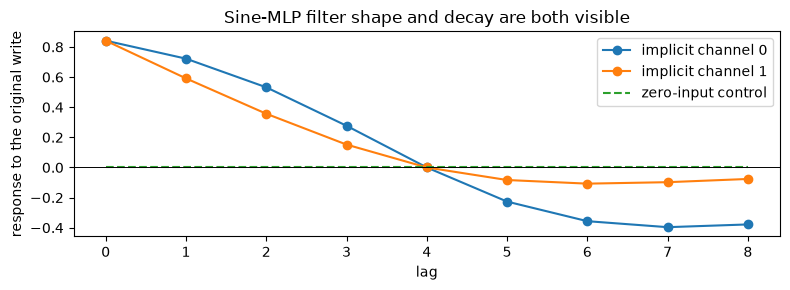

In [ ]:
W1=np.array([[0.],[1.],[0.]]);W2=np.array([[1.,1.]])
filters=implicit_filter(9,W1,W2,np.array([.1,.3]))
signal=np.zeros((9,2));signal[0]=1
filtered=fft_causal_convolution(signal,filters)
fig,ax=plt.subplots(figsize=(8,3))
for c in range(2):ax.plot(filtered[:,c],marker="o",label=f"implicit channel {c}")
ax.plot(fft_causal_convolution(np.zeros_like(signal),filters)[:,0],linestyle="--",label="zero-input control")
ax.axhline(0,color="black",linewidth=.7);ax.set(xlabel="lag",ylabel="response to the original write",title="Sine-MLP filter shape and decay are both visible");ax.legend();fig.tight_layout();plt.show()

<details>
<summary>Help - how should I interpret this?</summary>

With these supplied MLP weights the filter crosses zero near the midpoint and becomes negative. The faster decay shrinks later magnitudes. This is not failed language-model generation: it is an exact visualization of a signed filter. A learned readout or different filter can use that sign, but we have not trained one.

</details>

## Summary of 3️⃣

FFT acceleration must preserve causal linear convolution. An implicit filter can be long and signed; Hyena interleaves such filters with gates, so its full operator is richer than a single fixed convolution.

# 4️⃣ A hybrid stack on one controlled memory task

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Compose a recurrence residual followed by local attention. The recurrence gives each token access to accumulated state; local attention can move that information between nearby positions. This is a small supplied-weight attention–recurrence stack, not the complete Griffin architecture or a proof that a hybrid outperforms either family.

The frozen task writes one unit in channel zero at time zero, then presents eight empty gap/query positions. The query at every prefix asks for that same written value. We inspect the readout trace of RG-LRU, normalized scalar memory, addressed matrix memory, a Hyena filter and local attention on exactly this input. We also show a wrong-channel cue of the same norm and a recurrence reset control. Their failure tests the claim that the plotted readout depends on the intended write.

The comparison is intentionally mechanistic: gates and projections are fixed rather than trained under equal budgets, and different operators have different units/gains. Normalize each nonzero trace by its own first response to show fraction retained, and keep the raw final value for the forecast. Never relabel this figure an architecture accuracy leaderboard. A matched trained recall/state-tracking suite remains an explicit next study, not a hidden default experiment.

### Exercise - implement `hybrid_stack`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Compute `h=x+rg_lru_scan(x,...)`, then `h+local_attention(h@Wq,h@Wk,h@Wv,window)`. All matrices preserve channel width. This exposes how a later attention block reads a residual stream already carrying recurrence information. Reject a conceptual shortcut that averages the outputs of two separate models: that is an ensemble, not this sequential hybrid stack.

In [ ]:
def hybrid_stack(x, coefficients, input_gates, Wq, Wk, Wv, window):
    """A recurrent residual followed by a local-attention residual."""
    raise NotImplementedError()


tests.test_hybrid_stack(hybrid_stack)

<details>
<summary>Hint</summary>

Zeroing an attention value projection should remove only that residual branch, not the recurrence or original stream.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_hybrid_stack passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def hybrid_stack(x, coefficients, input_gates, Wq, Wk, Wv, window):
    """A recurrent residual followed by a local-attention residual."""
    h=x+rg_lru_scan(x,coefficients,input_gates)
    return h+local_attention(h@Wq,h@Wk,h@Wv,window)
```
</details>

### Exercise - implement `retained_fraction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Use the first element as the declared initial response; reject a zero or nonfinite first response rather than choosing a later maximum after inspecting the curve. Return a new array. This normalization separates memory retention from input gain but does not make different mechanisms equivalent. In particular a signed later fraction is a sign reversal, not a negative probability.

In [ ]:
def retained_fraction(trace):
    """Divide a scalar response trajectory by its first nonzero declared write."""
    raise NotImplementedError()


tests.test_retained_fraction(retained_fraction)

<details>
<summary>Hint</summary>

Do not shift the reference token or use each method's best later value as its denominator. That would hide input-gain and sign failures.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_retained_fraction passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def retained_fraction(trace):
    """Divide a scalar response trajectory by its first nonzero declared write."""
    trace=np.asarray(trace,dtype=float)
    if trace.ndim!=1 or len(trace)==0 or not np.isfinite(trace).all() or trace[0]==0:raise ValueError("Finite nonzero declared initial response required")
    return trace/trace[0]
```
</details>

### Exercise - implement `trace_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10–15 minutes on this exercise.
> ```

Require equal nonempty finite one-dimensional arrays and average squared differences. This metric is descriptive for the declared hand-specified readout, not an empirical trained-model comparison. Keep every query position, including sign reversals and zero responses. Dropping late positions because an attention window expired would change the question.

In [ ]:
def trace_error(trace, target):
    """Mean squared query-readout error with all query positions retained."""
    raise NotImplementedError()


tests.test_trace_error(trace_error)

<details>
<summary>Hint</summary>

A squared error of four at a −1 response is appropriate when the target is +1. Retain that failure.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_trace_error passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def trace_error(trace, target):
    """Mean squared query-readout error with all query positions retained."""
    trace=np.asarray(trace);target=np.asarray(target)
    if trace.shape!=target.shape or trace.ndim!=1 or len(trace)==0 or not np.isfinite(trace).all() or not np.isfinite(target).all():raise ValueError("Finite aligned query traces required")
    return float(np.mean((trace-target)**2))
```
</details>

## Signature result — trace the same write through five mechanisms


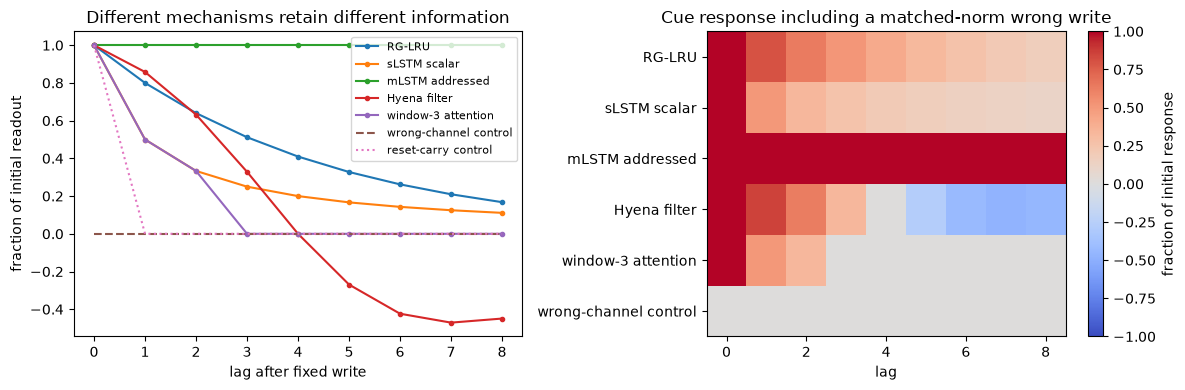

In [ ]:
x=np.zeros((9,2));x[0,0]=1.;wrong=x[:,::-1].copy()
rg=rg_lru_scan(x,.8,1)[:,0]
scalar=slstm_scan(x,0.,0.)[:,0]
keys=np.array([[1.,0.]]+[[0.,1.]]*8);queries=np.repeat([[1.,0.]],9,axis=0)
matrix=mlstm_scan(queries,keys,x,1.,1.)[0][:,0]
local=local_attention(np.zeros_like(x),np.zeros_like(x),x,3)[:,0]
filter_=implicit_filter(9,np.array([[0.],[1.],[0.]]),np.ones((1,2)),.1)
hyena=hyena_order_two(x,np.ones_like(x),np.ones_like(x),np.ones((1,2)),filter_)[:,0]
traces={"RG-LRU":rg,"sLSTM scalar":scalar,"mLSTM addressed":matrix,"Hyena filter":hyena,"window-3 attention":local}
wrong_control=rg_lru_scan(wrong,.8,1)[:,0]
reset_control=rg_lru_scan(x,.8,1,np.arange(9)>0)[:,0]
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,trace in traces.items():axes[0].plot(retained_fraction(trace),marker=".",label=name)
axes[0].plot(wrong_control,linestyle="--",label="wrong-channel control");axes[0].plot(reset_control/rg[0],linestyle=":",label="reset-carry control");axes[0].set(xlabel="lag after fixed write",ylabel="fraction of initial readout",title="Different mechanisms retain different information");axes[0].legend(fontsize=8)
hybrid=hybrid_stack(x,.8,1,np.eye(2),np.eye(2),np.eye(2),3)[:,0]
display(pd.DataFrame({**traces,"wrong-channel control":wrong_control,"hybrid raw":hybrid}))
matrix_plot=np.stack([retained_fraction(trace) for trace in traces.values()]+[wrong_control])
im=axes[1].imshow(matrix_plot,aspect="auto",cmap="coolwarm",vmin=-1,vmax=1);axes[1].set(yticks=range(6),yticklabels=[*traces,"wrong-channel control"],xlabel="lag",title="Cue response including a matched-norm wrong write");fig.colorbar(im,ax=axes[1],label="fraction of initial response")
fig.tight_layout();plt.show()
print("raw final RG/local",rg[-1],local[-1])
print("descriptive normalized trace MSE",{name:trace_error(retained_fraction(trace),np.ones(9)) for name,trace in traces.items()})

<details>
<summary>Help - how should I interpret this?</summary>

The local window loses the original write after lag two. RG-LRU retains a geometric fraction; scalar normalization dilutes the write with gap inputs. Matrix addressing avoids unrelated-key dilution under its supplied gates, while the signed Hyena filter reverses the cue. The wrong-channel control remains zero at the queried coordinate. The hybrid has a different raw gain because of residual composition; the printed table exposes it. These are equation-level trace differences on one task, not matched-trained model rankings.

</details>

## Interpreting the result

Long-memory support, stable numerical state, content addressing and a correct task readout are four different properties. A filter can retain a negative coefficient; a normalizer can dilute a write; an attention window can expire it. The figure is useful because each failure has a visible source in an implemented equation and an adjacent control.

## Try it yourself

Predict the raw RG-LRU final value when only its recurrence coefficient changes from 0.8 to 0.95. It retains a larger **fraction** but writes with a smaller initial gain. Which raw final value wins on this exact eight-lag task? Then change the task to latest-write revision by adding −1 in the same channel at the last position, preserving the original figure. Do not conflate a new gate with a newly trained model.

In [ ]:
play_a=.95
play=rg_lru_scan(x,play_a,1)[:,0]
display(pd.DataFrame({"a=.8 raw":rg,"a=.95 raw":play,"a=.95 fraction":retained_fraction(play),"wrong-channel control":rg_lru_scan(wrong,play_a,1)[:,0]}))
print("new raw final",play[-1])

## Limitations and native bridge ledger

| Requirement | Taught here | Still pending |
| --- | --- | --- |
| `modern.recurrent_gemma_griffin` | Stable RG-LRU coefficients, variance-scaled recurrence, resets, recurrent branch and local attention | Full learned Griffin/RecurrentGemma normalization/gate/MLP layout, training and optional released-checkpoint parity |
| `modern.xlstm` | Stabilized exponential scalar memory; value-by-key mLSTM state, signed normalizer and recurrent/parallel core equality | Learned sLSTM recurrent memory mixing, complete xLSTM blocks, stabilized native mLSTM and trained task suite |
| `modern.hyena` | Positional sine-MLP filter with decay, causal FFT oracle parity and order-two gated operator | Full positional/modulation/short-convolution stack, learned filters and native model comparison |
| `modern.hybrid_attention_ssm_rnn` | A sequential recurrence-residual/local-attention-residual stack and its inspectable trace | A matched trained recall/state-tracking suite across families, resource/performance measurement and broad generalization |

For a trained comparison, freeze a common synthetic task definition and exact train/development/evaluation examples, comparable parameter/optimization budgets, stopping and selection rules, all failures and seed aggregation before selecting a model. Preserve monitored development roles. Record actual recurrence state, conv cache and local KV reset behavior for a native bridge. No native budget is allocated here; no RecurrentGemma weights are downloaded by default.

# ☆ Bonus

## Anomaly hunt

Why can a larger recurrence coefficient produce a smaller initial write? When does its slower decay compensate? Derive the scalar response $\sqrt{1-a^2}a^t$ and compare two a values at a **predeclared** lag. For a changed state-tracking task, make a parity-update token rather than a pulse: which of these supplied mechanisms can implement a sign flip without retraining or adding a new state operation? A proposed architecture capability still needs that actual task and its controls.

## Further reading

- [Griffin](https://arxiv.org/abs/2402.19427): RG-LRU, recurrent blocks and local-attention hybrids.
- [Official RecurrentGemma](https://github.com/google-deepmind/recurrentgemma): version-specific model and cache contracts for a later parity bridge.
- [xLSTM](https://arxiv.org/abs/2405.04517): exponential gates, normalized scalar memories and matrix memories.
- [Official xLSTM implementation](https://github.com/NX-AI/xlstm): distinguish reference arithmetic from stabilized kernels and full blocks.
- [Hyena Hierarchy](https://arxiv.org/abs/2302.10866): implicit long filters interleaved with input-dependent gating.
- [Official Hyena code](https://github.com/HazyResearch/safari): inspect the filter, projection and convolution implementation before claiming native parity.